Joonseo Bang & KhevinJae

Background information : The dataset is about tic tac toe game with 958 instances and 9 features top-left-square, top-middle-square, top-right-square,middle-left-square, middle-middle-square, middle-right-square, bottom-left-square, bottom-middle-square, bottom-right-square. And each feature represents the state of one board box as x,o,b. In this assignment, we could handle whether the player X wins the game at the end of it or not by positive(if the player X wins) and negative(if the player X loses)

Main point : Whether can NB accurately classify Tic-Tac-Toe game outcomes without prior knowledge of the rule of winning?

Source link : https://archive.ics.uci.edu/dataset/101/tic+tac+toe+endgame

In [2]:
!pip install ucimlrepo

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [6]:
column_names = [
    'Top_Left', 'Top_Middle', 'Top_Right',
    'Middle_Left', 'Middle_Middle', 'Middle_Right',
    'Bottom_Left', 'Bottom_Middle', 'Bottom_Right',
    'Class'
]

df = pd.read_csv(
    'tic-tac-toe.data',
    header=None,
    names=column_names
)

# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class']

print("Dataset Overview")
print("Total samples:", df.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())

print("\nFirst 5 rows:")
print(df.head())

print("\nClass distribution:")
print(y.value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset Overview
Total samples: 958
Number of features: 9
Number of classes: 2

First 5 rows:
  Top_Left Top_Middle Top_Right Middle_Left Middle_Middle Middle_Right  \
0        x          x         x           x             o            o   
1        x          x         x           x             o            o   
2        x          x         x           x             o            o   
3        x          x         x           x             o            o   
4        x          x         x           x             o            o   

  Bottom_Left Bottom_Middle Bottom_Right     Class  
0           x             o            o  positive  
1           o             x            o  positive  
2           o             o            x  positive  
3           o             b            b  positive  
4           b             o            b  positive  

Class distribution:
Class
positive    626
negative    332
Name: count, dtype: int64

Missing values:
Top_Left         0
Top_Middle       0
Top

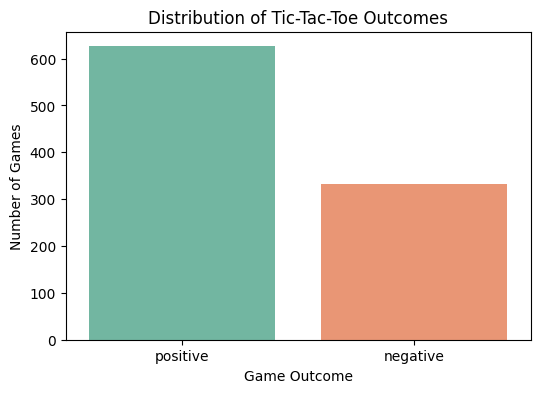

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette='Set2',
    legend=False
)

plt.xlabel('Game Outcome')
plt.ylabel('Number of Games')
plt.title('Distribution of Tic-Tac-Toe Outcomes')

plt.show()

This dataset consists of 958 instances and 9 categorical features representing the 9 squares of a Tic-Tac-Toe game board. The target variable is classified as 'positive' if player X wins, and 'negative' otherwise.

And since the "positive" exceeds "negative", there is a slight class imbalance.

In [8]:
X = df.drop('Class', axis=1)
y = df['Class']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
  Top_Left Top_Middle Top_Right Middle_Left Middle_Middle Middle_Right  \
0        x          x         x           x             o            o   
1        x          x         x           x             o            o   
2        x          x         x           x             o            o   
3        x          x         x           x             o            o   
4        x          x         x           x             o            o   

  Bottom_Left Bottom_Middle Bottom_Right  
0           x             o            o  
1           o             x            o  
2           o             o            x  
3           o             b            b  
4           b             o            b  

Target:
0    positive
1    positive
2    positive
3    positive
4    positive
Name: Class, dtype: object


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 766
Testing samples: 192


In [10]:
encoder = OrdinalEncoder(
    categories=[['b', 'o', 'x']] * 9,
    dtype=int
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Original data:")
print(X_train.head())

print("\nEncoded data:")
print(X_train_encoded[:5])

Original data:
    Top_Left Top_Middle Top_Right Middle_Left Middle_Middle Middle_Right  \
59         x          x         x           b             o            o   
866        o          b         x           b             o            b   
132        x          o         x           o             o            x   
688        x          o         x           b             o            b   
183        x          o         o           b             x            b   

    Bottom_Left Bottom_Middle Bottom_Right  
59            o             b            x  
866           x             x            o  
132           o             x            x  
688           x             o            b  
183           o             x            x  

Encoded data:
[[2 2 2 0 1 1 1 0 2]
 [1 0 2 0 1 0 2 2 1]
 [2 1 2 1 1 2 1 2 2]
 [2 1 2 0 1 0 2 1 0]
 [2 1 1 0 2 0 1 2 2]]


The dataset is split into a training set and a test set in an 80:20 ratio. An OrdinalEncoder is used to convert categorical values in numerical form. Since Naive Bayes calculates conditional probabilities rather than distances between observations, feature scaling is not required.

In [11]:
model = CategoricalNB(alpha=1.0)

model.fit(X_train_encoded, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [12]:
y_pred = model.predict(X_test_encoded)

# Calculate prediction probabilities
probabilities = model.predict_proba(X_test_encoded)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Overall Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Overall Accuracy: 68.75%

Classification Report:
              precision    recall  f1-score   support

    negative       0.59      0.34      0.43        67
    positive       0.71      0.87      0.78       125

    accuracy                           0.69       192
   macro avg       0.65      0.61      0.61       192
weighted avg       0.67      0.69      0.66       192



The model achieved an overall accuracy of 68.75%. The recall for the positive class was 0.87, whereas the recall for the negative class was only 0.34.

Text(0.5, 1.0, 'Confusion Matrix - Tic-Tac-Toe')

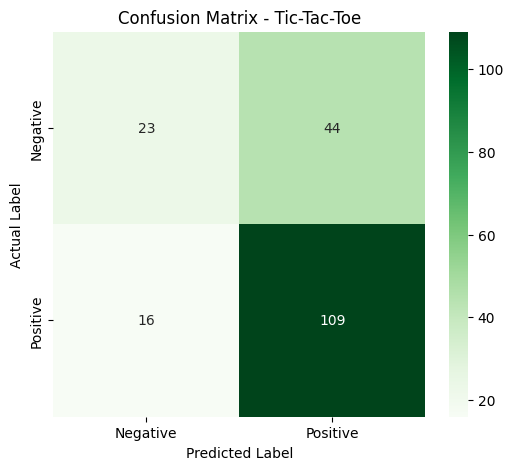

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['negative', 'positive']
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Tic-Tac-Toe')


According to above, the model correctly classified 132 out of 192 instances. However, there were 44 false positives and 16 false negatives, suggesting that the model has a tendency to classify game outcomes as 'positive.'

In [14]:
new_games = pd.DataFrame([
    ['x', 'x', 'x',
     'o', 'o', 'b',
     'b', 'b', 'b'],

    ['o', 'o', 'o',
     'x', 'x', 'b',
     'x', 'b', 'b'],

    ['x', 'o', 'x',
     'x', 'o', 'o',
     'o', 'x', 'x']

], columns=X.columns)

# Convert categorical values
new_encoded = encoder.transform(new_games)

# Make predictions
predictions = model.predict(new_encoded)
probabilities = model.predict_proba(new_encoded)

# Display results
for i in range(len(new_games)):

    print(f"Game #{i+1}")

    print("Prediction:", predictions[i])

    for cls, prob in zip(
        model.classes_,
        probabilities[i]
    ):
        print(f"{cls}: {prob:.2%}")

    print()

Game #1
Prediction: positive
negative: 29.46%
positive: 70.54%

Game #2
Prediction: positive
negative: 20.51%
positive: 79.49%

Game #3
Prediction: positive
negative: 49.76%
positive: 50.24%



It shows the all three example positive even the Game #2 was won by player O, and the Game #3 ended with draw which shows that NB does not directly learn the winning rules of Tic-Tac-Toe

In conclusion, a categorical NB(Naive Bayes) was applied to classify the outcomes of Tic-Tac-Toe games using nine categorical features. The model finally achieved an acurracy of 68.75%


Otherwise, the model performed better at identifying positive outcomes than negative outcomes which is shown in class imbalance.


In addition, it had limitation of conditional independence, which is the frame of NB. And in the process of Tic-Tac-Toe game, this conditional independence could act as a constraint part during the classification of model's performance.

Overall, we demonstrated how NB can be applied to categorical classification situation and it showed how the characteristics of dataset can affect model performance.